# Assignment 1

### Students: <br>
Anton Maksymchuk Netterström <br>
Mauritz Almgren

Following dependencies is required to run the code

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


Data fetching and preprocessing

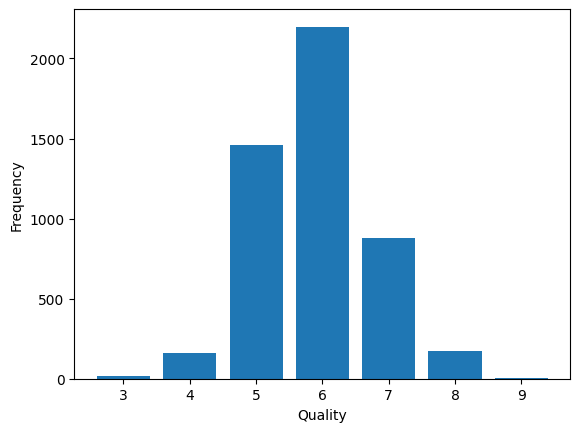

Unique quality quality
6    2198
5    1457
7     880
8     175
4     163
3      20
9       5
Name: count, dtype: int64


In [80]:
df = pd.read_csv('winequality-white.csv', sep=';')

# Get value for each 'quality' 
count_unique = df['quality'].value_counts()

# Bar chart for quality BEFORE SMOTE
plt.bar(count_unique.index, count_unique.values)
plt.xlabel('Quality')
plt.ylabel('Frequency')
plt.show()


print('Unique quality', count_unique)


In [81]:
# Data splitting - Baseline. Let X be all columns exepct quality and let Y be the column quality
X = df.drop(columns=['quality'])
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


Logistic regression classifier (with solver lbfgs as this is a multiclass classification problem)

In [82]:
# Logistic Regression classifier (lbfgs)
rkf = RepeatedStratifiedKFold(n_splits=3, n_repeats=10, random_state=42)
rkf.get_n_splits()
pipe = Pipeline([('scaler', StandardScaler()), ('classifier', LogisticRegression(solver='lbfgs', max_iter=2000))])
scores = cross_val_score(pipe, X_train, y_train, cv=rkf, scoring='f1_macro')


print(f"Cross-validation accuracy scores: {scores}")
print(f"Mean CV accuracy: {np.mean(scores):.4f}")
print(f"Standard deviation of CV accuracy: {np.std(scores):.4f}")

Cross-validation accuracy scores: [0.20618191 0.21978109 0.24354059 0.22841862 0.23379555 0.28212981
 0.24120611 0.27247924 0.20538663 0.27265727 0.22130133 0.22195812
 0.23269417 0.2191153  0.23051513 0.22157889 0.21247191 0.23443708
 0.22429616 0.2384661  0.21472071 0.22369465 0.22941083 0.21681519
 0.22967432 0.22249126 0.22299516 0.28102603 0.21707468 0.22863846]
Mean CV accuracy: 0.2316
Standard deviation of CV accuracy: 0.0200


Random forest classifier

In [83]:
# Random forest classifier
pipe2 = Pipeline([('scalar', StandardScaler()), ('classifier', RandomForestClassifier(random_state=42))])
scores = cross_val_score(pipe2, X_train, y_train, cv=rkf, scoring='f1_macro')


print(f"Cross-validation F1 score: {scores}")
print(f"Mean CV F1 score: {np.mean(scores):.4f}")
print(f"Standard deviation of CV F1 score: {np.std(scores):.4f}")


Cross-validation F1 score: [0.34611769 0.33200189 0.38292682 0.36824223 0.35895863 0.34849427
 0.36335716 0.3406071  0.37466667 0.35588113 0.36669018 0.35854347
 0.38444652 0.3485748  0.34496237 0.38116627 0.36396055 0.34430282
 0.36541568 0.35952266 0.35108751 0.34276368 0.32948291 0.38114401
 0.36752094 0.3755807  0.36566085 0.37323127 0.37777469 0.39373337]
Mean CV F1 score: 0.3616
Standard deviation of CV F1 score: 0.0160


As Random forest classifier gave the 'best' F1 Macro, Random forest will be used for final test

In [84]:
pipe2.fit(X_train, y_train)

# Predict on held-out test set
y_pred = pipe2.predict(X_test)

# Evaluate
f1_macro = f1_score(y_test, y_pred, average='macro')

print(f"Final test F1 Macro: {f1_macro:.4f}")

report_without_SMOTE = classification_report(y_test, y_pred, zero_division=0)
print(report_without_SMOTE)

Final test F1 Macro: 0.4277
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.70      0.21      0.33        33
           5       0.71      0.66      0.68       291
           6       0.64      0.82      0.72       440
           7       0.71      0.48      0.58       176
           8       0.95      0.54      0.69        35
           9       0.00      0.00      0.00         1

    accuracy                           0.68       980
   macro avg       0.53      0.39      0.43       980
weighted avg       0.68      0.68      0.66       980



Smote implementation

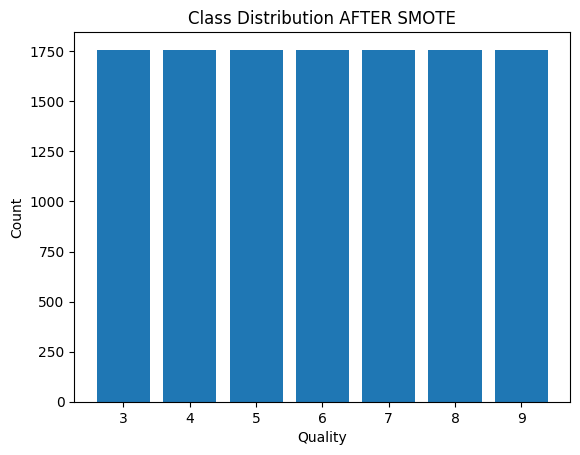

In [85]:
smote = SMOTE(sampling_strategy='not majority', random_state=42, k_neighbors=1)

X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

plt.bar(y_train_sm.value_counts().index, y_train_sm.value_counts().values)
plt.xlabel('Quality')
plt.ylabel("Count")
plt.title("Class Distribution AFTER SMOTE")
plt.show()


Logistic regression and random forest classifier with SMOTE implementation

In [86]:
pipe_lr = ImbPipeline([('scalar', StandardScaler()), ('smote', smote), ('classifier', LogisticRegression(solver='lbfgs', max_iter=2000))])
scores = cross_val_score(pipe_lr, X_train, y_train, cv=rkf, scoring='f1_macro')

print(f"Cross-validation F1 score: {scores}")
print(f"Mean CV F1 score: {np.mean(scores):.4f}")
print(f"Standard deviation of CV F1 score: {np.std(scores):.4f}")

Cross-validation F1 score: [0.21821168 0.23087677 0.22353386 0.21848908 0.22254869 0.22031948
 0.19748447 0.2158576  0.21011748 0.21413288 0.21502402 0.20920718
 0.22258616 0.21718049 0.22320265 0.2117479  0.22035548 0.19463502
 0.22145837 0.21148711 0.23083073 0.20398855 0.21570747 0.22736431
 0.22681481 0.22299953 0.21969839 0.22343317 0.18400488 0.20958405]
Mean CV F1 score: 0.2161
Standard deviation of CV F1 score: 0.0103


In [ ]:
pipe_rf = ImbPipeline([('scalar', StandardScaler()), ('smote', smote), ('classifier', RandomForestClassifier(random_state=42))])
scores = cross_val_score(pipe_rf, X_train, y_train, cv=rkf, scoring='f1_macro')


print(f"Cross-validation accuracy scores: {scores}")
print(f"Mean CV accuracy: {np.mean(scores):.4f}")
print(f"Standard deviation of CV accuracy: {np.std(scores):.4f}")

Final balanced training and testing for random forest classifier

In [ ]:
pipe_rf.fit(X_train, y_train)

y_pred = pipe_rf.predict(X_test)

f1_macro = f1_score(y_test, y_pred, average='macro')

print(f"Final test Macro F1: {f1_macro:.4f}")

report_with_SMOTE = classification_report(y_test, y_pred, zero_division=0)
print(report_with_SMOTE)

Final test Macro F1: 0.4344
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.48      0.42      0.45        33
           5       0.68      0.67      0.68       291
           6       0.67      0.69      0.68       440
           7       0.60      0.61      0.60       176
           8       0.69      0.57      0.62        35
           9       0.00      0.00      0.00         1

    accuracy                           0.66       980
   macro avg       0.45      0.42      0.43       980
weighted avg       0.65      0.66      0.65       980

